## Evaluation of XAI Experiment in Toloka (Danish Fungi)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
plt.style.use(['science', 'no-latex'])

stats = {
    'Control': pd.read_csv('./beexplainable/toloka/fungi/experiment_200_1/Toloka_Fungi_Control_200_1_accepted.tsv',
                           sep = '\t'),
    'Control_Conf':pd.read_csv('./beexplainable/toloka/fungi/experiment_200_1/Toloka_Fungi_Control_Conf_200_1_accepted.tsv',
                           sep = '\t'),
    'Concepts_KNN':pd.read_csv('./beexplainable/toloka/fungi/experiment_200_1/Toloka_Fungi_Concepts_KNN_200_1_accepted.tsv',
                           sep = '\t'),
    'Concepts_TCAV':pd.read_csv('./beexplainable/toloka/fungi/experiment_200_1/Toloka_Fungi_Concepts_TCAV_200_1_accepted.tsv',
                           sep = '\t'),
    'Examples_GradSim':pd.read_csv('./beexplainable/toloka/fungi/experiment_200_1/Toloka_Fungi_Examples_GradSim_200_1_accepted.tsv',
                           sep = '\t'),
    'Examples_RepPoint':pd.read_csv('./beexplainable/toloka/fungi/experiment_200_1/Toloka_Fungi_Examples_RepPoint_200_1_accepted.tsv',
                           sep = '\t')
}

#classes = np.array( ["Russula emetica", "Russula paludosa", "Russula rosea"] )
num_samples_per_task = 10.0

In [2]:
# How many different users are there?
# Note: banned users are not listed
num_users = {}
for group in stats:
    num_users[group] = stats[group]['ASSIGNMENT:assignment_id'].nunique()
    print(group + ' group has ' + str(num_users[group]) + ' accepted users.')

Control group has 120 accepted users.
Control_Conf group has 129 accepted users.
Concepts_KNN group has 119 accepted users.
Concepts_TCAV group has 110 accepted users.
Examples_GradSim group has 122 accepted users.
Examples_RepPoint group has 130 accepted users.


In [3]:
# Get accuracies per tasks
task_stats = {'Control':           {'Task_1': [], 'Task_2': [], 'Task_3': []},
              'Control_Conf':      {'Task_1': [], 'Task_2': [], 'Task_3': []},
              'Concepts_KNN':      {'Task_1': [], 'Task_2': [], 'Task_3': []},
              'Concepts_TCAV':     {'Task_1': [], 'Task_2': [], 'Task_3': []},
              'Examples_GradSim':  {'Task_1': [], 'Task_2': [], 'Task_3': []},
              'Examples_RepPoint': {'Task_1': [], 'Task_2': [], 'Task_3': []}}
for group in stats:
    for asign_id, user in stats[group].groupby(by='ASSIGNMENT:assignment_id'):

        t1, t2, t3 = user.iloc[:10, :], user.iloc[10:20, :], user.iloc[20:30, :]
        task_stats[group]['Task_1'].append((t1['OUTPUT:result'] == t1['GOLDEN:result']).sum())
        task_stats[group]['Task_2'].append((t2['OUTPUT:result'] == t2['GOLDEN:result']).sum())
        task_stats[group]['Task_3'].append((t3['OUTPUT:result'] == t3['GOLDEN:result']).sum())

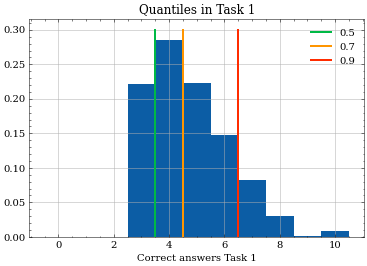

In [5]:
# Plot scores in Task 1 for all groups together
corrects_1 = task_stats['Control']['Task_1'] + task_stats['Control_Conf']['Task_1'] + \
             task_stats['Concepts_KNN']['Task_1'] + task_stats['Concepts_TCAV']['Task_1'] + \
             task_stats['Examples_GradSim']['Task_1'] + task_stats['Examples_RepPoint']['Task_1']

# Compute various quantiles
qs = [0.5, 0.7, 0.9]
corrects_1_q = [np.quantile(corrects_1, q) for q in qs]

# Plot histogram of scores for all users in Task 1
plt.hist(corrects_1, bins = np.arange(num_samples_per_task+2)-0.5, density = True)
for cq in corrects_1_q:
    plt.plot([cq-0.5, cq-0.5], [0.0, 0.3], lw=2)
plt.xlabel('Correct answers Task 1')
plt.title('Quantiles in Task 1')
plt.legend(qs)
plt.grid()
plt.show()

The median over all answers in Task 1 lies at 4 correct answers.

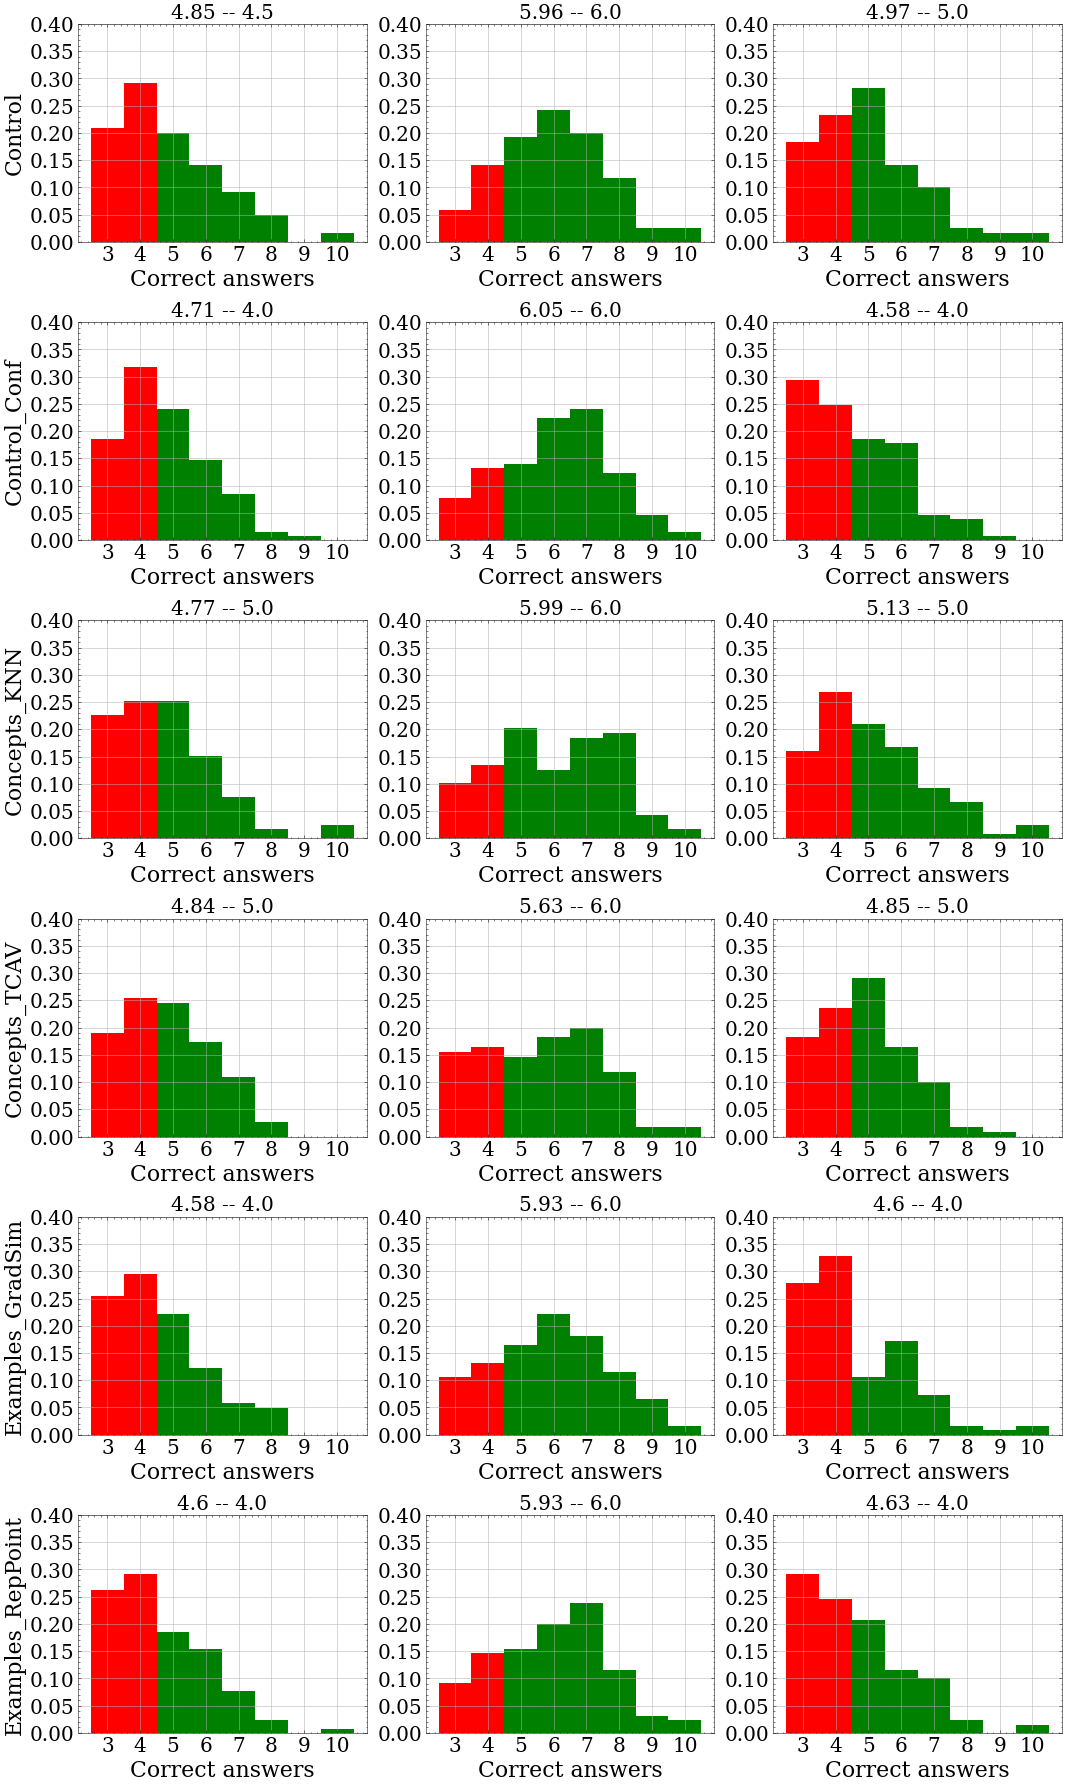

In [8]:
# Novices-Experts split w.r.t. median
fontsize = 20
plt.figure(figsize=(15, 25))
for j, group in enumerate(task_stats):
    for i, task in enumerate(task_stats[group]):

        plt.subplot(len(task_stats), 3, 3*j+i+1)
        n, _, patches = plt.hist(task_stats[group][task],
                                 bins = np.arange(3, num_samples_per_task+2)-0.5, density = True, color = 'red')
        plt.setp(patches[-6:], 'facecolor', 'green')
        plt.xlabel('Correct answers', fontsize=fontsize+2)
        plt.ylim(0.0, 0.4)
        #plt.title(task.replace('_', ' '), fontsize=fontsize+5)
        plt.title(str(np.round(np.mean(task_stats[group][task]), 2)) + ' -- ' + str(np.median(task_stats[group][task])),
                  fontsize=fontsize)
        if i % 3 == 0: plt.ylabel(group,  fontsize=fontsize+2)
        plt.xticks(fontsize=fontsize); plt.yticks(fontsize=fontsize)
        plt.grid()
plt.tight_layout()
plt.show()

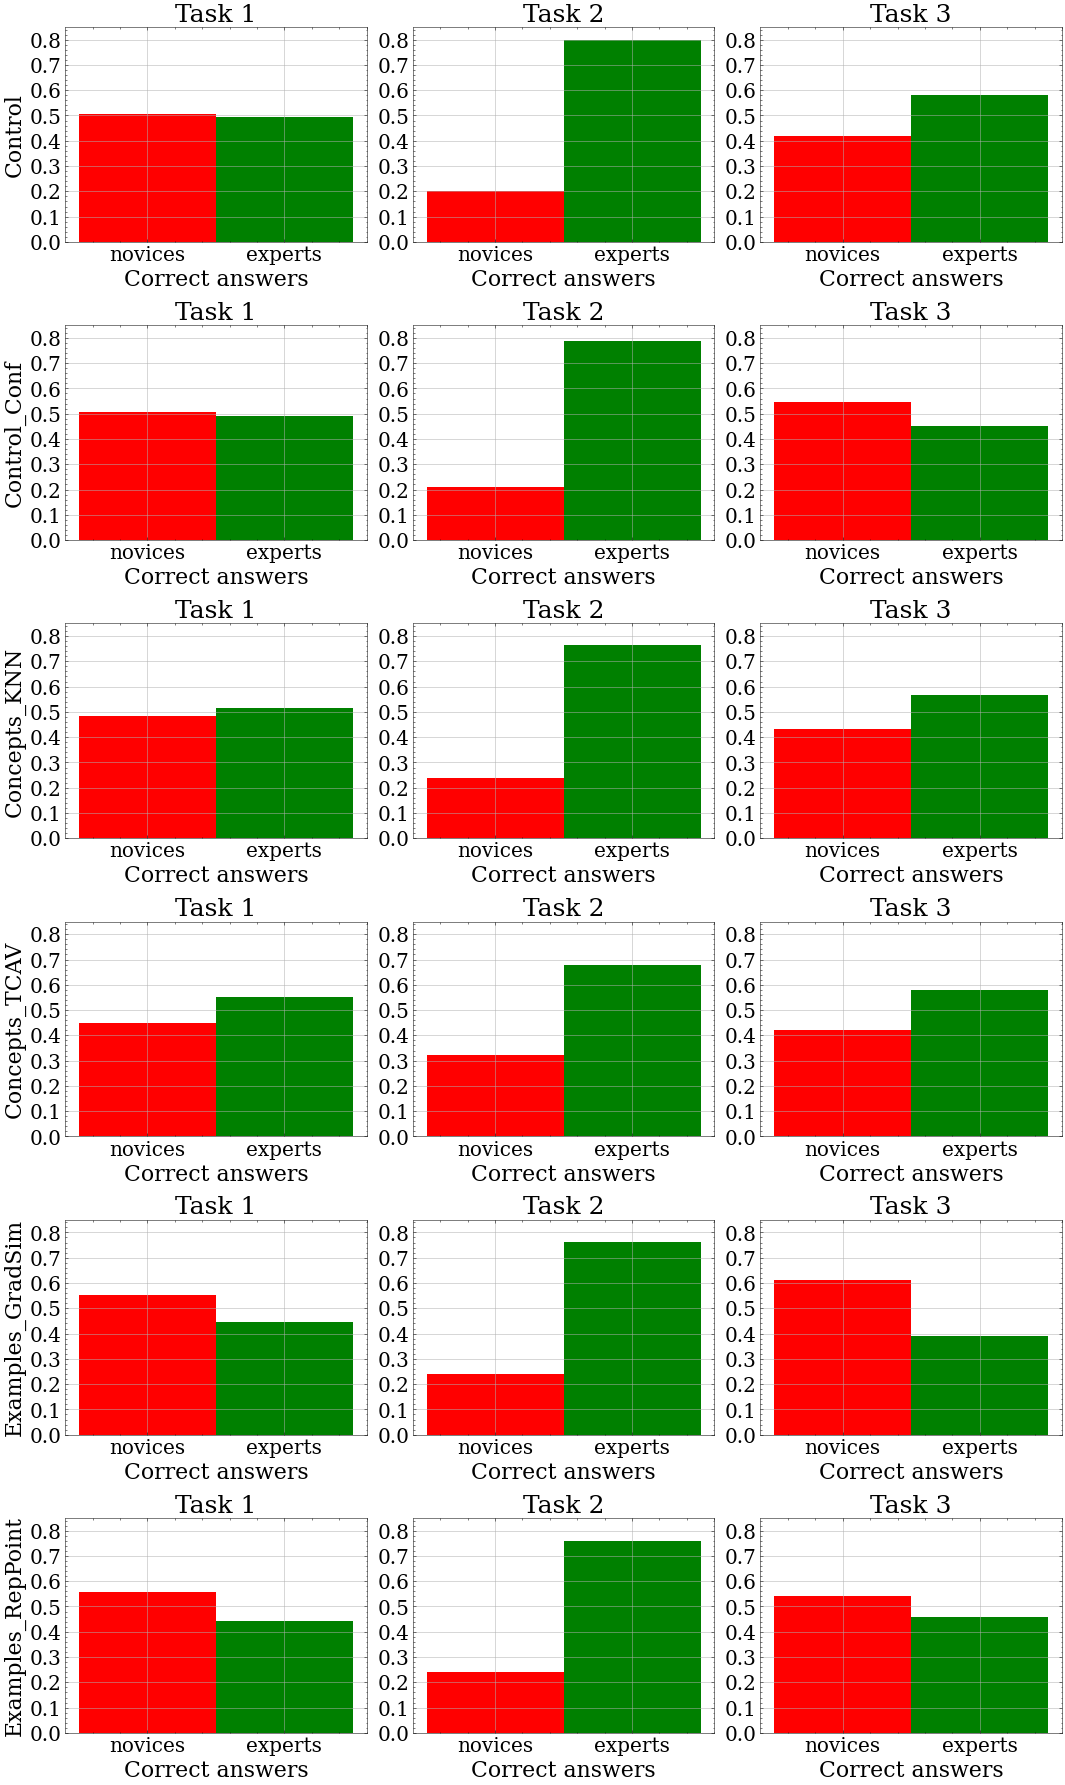

In [10]:
# Novices-Experts split w.r.t. median
fontsize = 20
plt.figure(figsize=(15, 25))
for j, group in enumerate(task_stats):
    for i, task in enumerate(task_stats[group]):

        plt.subplot(len(task_stats), 3, 3*j+i+1)
        num_novices = np.count_nonzero(np.asarray(task_stats[group][task]) < 5)
        nov_exp_ticks = ['novices'] * num_novices \
                        + ['experts'] * ((stats[group]['ASSIGNMENT:assignment_id'].nunique())-1 - num_novices)
        n, _, patches = plt.hist(nov_exp_ticks, bins = np.arange(3)-0.5, density = True, color = 'red')
        plt.setp(patches[1], 'facecolor', 'green')
        plt.xlabel('Correct answers', fontsize=fontsize+2)
        plt.ylim(0.0, 0.85)
        plt.title(task.replace('_', ' '), fontsize=fontsize+5)
        if i % 3 == 0: plt.ylabel(group,  fontsize=fontsize+2)
        plt.xticks(fontsize=fontsize); plt.yticks(fontsize=fontsize)
        plt.grid()
plt.tight_layout()
plt.show()

### Agreement Rate

In [11]:
# One-based indexes Tasks 1+3:
loaded_soft = np.load('./beexplainable/metafiles/Fungi/raw/softmax_preds.npy')
IMAGES_PATH = './beexplainable/metafiles/Fungi/raw/images.txt'
classes = ['emetica', 'paludosa', 'rosea']
from beexplainable.beexplainable.utils import metafile_readers as mr
img_dict = mr.metafile_to_dict(IMAGES_PATH)
for img_id in img_dict: # remove parent species folder name
    img_dict[img_id] = img_dict[img_id].split('/')[1]
img_dict['1']

'2874312351-289519.JPG'

In [12]:
# How often did users agree with the AI's hints in Task 1
print('Agreement TASK 1')
for group in stats:
    agree_rate_t1 = 0.0
    for asign_id, user in stats[group].groupby(by='ASSIGNMENT:assignment_id'):
        t1 = user.iloc[:10,:]
        model_preds_t1 = []
        for img in t1['INPUT:image']:
            substr = img.split('/')[-1].split('.')[0].split('-')[:2]
            orig_name = '-'.join(substr) + '.JPG'
            orig_id = list(img_dict.keys())[list(img_dict.values()).index(orig_name)]
            pred_cls = np.argmax(loaded_soft[int(orig_id)-1], axis=-1)
            model_preds_t1.append(classes[ pred_cls ])

        agree_rate_t1 += (model_preds_t1 == t1['OUTPUT:result']).sum()
    print(group + ': users agreed ' + str(np.round(agree_rate_t1/num_users[group]*10, 2)) + '% of the times with the AI.')

Agreement TASK 1
Control: users agreed 42.0% of the times with the AI.
Control_Conf: users agreed 42.87% of the times with the AI.
Concepts_KNN: users agreed 41.43% of the times with the AI.
Concepts_TCAV: users agreed 42.0% of the times with the AI.
Examples_GradSim: users agreed 40.66% of the times with the AI.
Examples_RepPoint: users agreed 39.62% of the times with the AI.


In [13]:
# How often did users agree with the AI's hints in Task 2
print('Agreement TASK 2')
for group in stats:
    agree_rate_t2 = 0.0
    for asign_id, user in stats[group].groupby(by='ASSIGNMENT:assignment_id'):
        t2 = user.iloc[10:20,:]
        model_preds_t2 = []
        for img in t2['INPUT:image']:
            substr = img.split('/')[-1].split('.')[0].split('-')[:2]
            orig_name = '-'.join(substr) + '.JPG'
            orig_id = list(img_dict.keys())[list(img_dict.values()).index(orig_name)]
            pred_cls = np.argmax(loaded_soft[int(orig_id)-1], axis=-1)
            model_preds_t2.append(classes[ pred_cls ])

        agree_rate_t2 += (model_preds_t2 == t2['OUTPUT:result']).sum()
    print(group + ': users agreed ' + str(np.round(agree_rate_t2/num_users[group]*10, 2)) + '% of the times with the AI.')

Agreement TASK 2
Control: users agreed 64.33% of the times with the AI.
Control_Conf: users agreed 67.52% of the times with the AI.
Concepts_KNN: users agreed 64.87% of the times with the AI.
Concepts_TCAV: users agreed 61.0% of the times with the AI.
Examples_GradSim: users agreed 64.75% of the times with the AI.
Examples_RepPoint: users agreed 65.31% of the times with the AI.


In [14]:
# How often did users agree with the AI's hints in Task 2, when they were wrong
print('Agreement TASK 2 WRONG')
for group in stats:
    agree_rate_t2_w, total_wrong = 0.0, 0
    for asign_id, user in stats[group].groupby(by='ASSIGNMENT:assignment_id'):
        t2 = user.iloc[10:20,:]
        for i, img in enumerate(t2['INPUT:image']):
            if 'wrong' in img:
                total_wrong += 1
                substr = img.split('/')[-1].split('.')[0].split('-')[:2]
                orig_name = '-'.join(substr) + '.JPG'
                orig_id = list(img_dict.keys())[list(img_dict.values()).index(orig_name)]
                pred_cls = np.argmax(loaded_soft[int(orig_id)-1], axis=-1)
                if classes[pred_cls] in t2.iloc[i]['OUTPUT:result']:
                    agree_rate_t2_w += 1

    print(group + ': users agreed ' + str(np.round(agree_rate_t2_w/total_wrong*100, 2)) + '% of the times with the WRONG AI hint.')
    print(str(total_wrong) + ' of the ' + str(10*num_users[group]) + ' images in Task 2 had a wrong AI prediction.\n')

Agreement TASK 2 WRONG
Control: users agreed 51.28% of the times with the WRONG AI hint.
312 of the 1200 images in Task 2 had a wrong AI prediction.

Control_Conf: users agreed 55.49% of the times with the WRONG AI hint.
319 of the 1290 images in Task 2 had a wrong AI prediction.

Concepts_KNN: users agreed 51.56% of the times with the WRONG AI hint.
289 of the 1190 images in Task 2 had a wrong AI prediction.

Concepts_TCAV: users agreed 51.28% of the times with the WRONG AI hint.
273 of the 1100 images in Task 2 had a wrong AI prediction.

Examples_GradSim: users agreed 51.45% of the times with the WRONG AI hint.
311 of the 1220 images in Task 2 had a wrong AI prediction.

Examples_RepPoint: users agreed 53.33% of the times with the WRONG AI hint.
330 of the 1300 images in Task 2 had a wrong AI prediction.



In [15]:
# How often did users agree with the AI's hints in Task 3
print('Agreement TASK 3')
for group in stats:
    agree_rate_t3 = 0.0
    for asign_id, user in stats[group].groupby(by='ASSIGNMENT:assignment_id'):
        t3 = user.iloc[20:30,:]
        model_preds_t3 = []
        for img in t3['INPUT:image']:
            substr = img.split('/')[-1].split('.')[0].split('-')[:2]
            orig_name = '-'.join(substr) + '.JPG'
            orig_id = list(img_dict.keys())[list(img_dict.values()).index(orig_name)]
            pred_cls = np.argmax(loaded_soft[int(orig_id)-1], axis=-1)
            model_preds_t3.append(classes[ pred_cls ])

        agree_rate_t3 += (model_preds_t3 == t3['OUTPUT:result']).sum()
    print(group + ': users agreed ' + str(np.round(agree_rate_t3/num_users[group]*10, 2)) + '% of the times with the AI.')

Agreement TASK 3
Control: users agreed 44.08% of the times with the AI.
Control_Conf: users agreed 41.24% of the times with the AI.
Concepts_KNN: users agreed 44.12% of the times with the AI.
Concepts_TCAV: users agreed 44.27% of the times with the AI.
Examples_GradSim: users agreed 40.25% of the times with the AI.
Examples_RepPoint: users agreed 41.46% of the times with the AI.
